> **결함판(참고용)**: 이 노트북은 σ 전파 오류(GARCH·SV)와 드리프트 비교 조건 불일치가 있는 초기 파이프라인 결과다. 현재 기준은 상위 폴더의 `8-2`~`8-5`이고, 검증 내용은 `8-6(참고)`에 있다. 원본 출력은 그대로 보존했다(재실행 시 경로는 이 폴더 기준).

# 8-3. auto_arima(KPSS/ADF)·GARCH/SV(AIC) 성능저하 증명

`8-2`에서 d=1, p=1을 "기본상태"로 우선 썼는데, 이 값이 실제로 맞는지 확인한다. 여기서는 **왜 자동 파라미터 선택(KPSS/ADF 기반 d, AIC 기반 p)을 못 믿는지**를 out-of-sample 커버리지·MSE·CRPS로 증명하는 데까지만 다룬다 -- 이후 d,p를 실제로 최적화하는 계산은 `8-4`에서 이어간다(계산량이 커서 분리).

**흐름**: (A) d 선택(KPSS/ADF) 문제 -> (B) p 선택(AIC, GARCH/SV) 문제


In [1]:
import warnings
warnings.filterwarnings("ignore")
import os
import numpy as np
import pandas as pd
import pmdarima as pm
import properscoring as ps
from arch import arch_model
from scipy.optimize import minimize
from scipy import stats

H = 4
MIN_TRAIN = 20
INITIAL_CALIB = 15
TARGET_VAR = "X3_l1"
ALPHA = 0.10
Z = stats.norm.ppf(1 - ALPHA / 2)
D_FIXED = 1

raw = pd.read_csv("../../../data/gold/gold_major_variables.csv")
raw = raw[raw["quarter"].notna()].reset_index(drop=True)
vals = raw[["quarter", TARGET_VAR]].dropna()[TARGET_VAR].values.astype(float)
n = len(vals)
var_std = vals.std()
origins = list(range(MIN_TRAIN, n - H + 1))
scored_origins = origins[INITIAL_CALIB:]
print(f"채점 origin {len(scored_origins)}개")


def score_hvals(fc, conf, actual):
    crps_hs, cov_hs, mse_hs = [], [], []
    for hh in range(H):
        sig_hh = max((conf[hh, 1] - conf[hh, 0]) / (2 * Z), 1e-6)
        crps_hs.append(ps.crps_gaussian(actual[hh], mu=fc[hh], sig=sig_hh) / var_std)
        cov_hs.append(1.0 if conf[hh, 0] <= actual[hh] <= conf[hh, 1] else 0.0)
        mse_hs.append(((actual[hh] - fc[hh]) / var_std) ** 2)
    return np.mean(cov_hs) * 100, np.mean(mse_hs), np.mean(crps_hs)


채점 origin 22개


## A. d 선택(KPSS/ADF) 문제

auto_arima 기본값(KPSS)이 실제로 고른 (p,d,q)와, KPSS/ADF/d=1고정 세 방식의 out-of-sample 성능을 비교한다.


In [2]:
order_rows = []
for origin in scored_origins:
    train, actual = vals[:origin], vals[origin:origin + H]
    m = pm.auto_arima(train, seasonal=False, suppress_warnings=True, error_action="ignore", information_criterion="aic")
    fc, conf = m.predict(n_periods=H, return_conf_int=True, alpha=ALPHA)
    cov, mse, crps = score_hvals(np.asarray(fc), conf, actual)
    order_rows.append({"origin": origin, "order(p,d,q)": m.order, "커버리지": cov, "MSE": mse, "CRPS": crps})

order_df = pd.DataFrame(order_rows)
display(order_df.head(8))
print("\norder별 선택 빈도:")
print(order_df["order(p,d,q)"].value_counts())
print(f"\ntest=kpss(기본값) 평균 -- 커버리지 {order_df['커버리지'].mean():.1f}%, MSE {order_df['MSE'].mean():.3f}, CRPS {order_df['CRPS'].mean():.3f}")


,origin,"order(p,d,q)",커버리지,MSE,CRPS
0,35,"(2, 0, 1)",0.0,0.789638,0.675679
1,36,"(1, 0, 2)",75.0,0.299306,0.304917
2,37,"(1, 0, 3)",100.0,0.229438,0.261898
3,38,"(2, 0, 1)",0.0,0.513079,0.526297
4,39,"(1, 0, 4)",75.0,0.126972,0.241158
5,40,"(4, 0, 0)",50.0,0.329307,0.317571
6,41,"(4, 0, 0)",50.0,0.455868,0.442276
7,42,"(4, 0, 0)",50.0,0.280496,0.364168



order별 선택 빈도:
order(p,d,q)
(2, 0, 0)    9
(2, 0, 1)    4
(4, 0, 0)    3
(4, 0, 1)    2
(1, 0, 2)    1
(1, 0, 3)    1
(1, 0, 4)    1
(0, 1, 1)    1
Name: count, dtype: int64

test=kpss(기본값) 평균 -- 커버리지 51.1%, MSE 1.176, CRPS 0.639


**발견**: 22개 중 21개가 d=0을 고른다 -- AIC가 아니라 **KPSS 검정**이 먼저 d를 정하기 때문이다.


In [3]:
from statsmodels.tsa.stattools import kpss, adfuller

test_rows = []
for origin in scored_origins:
    train = vals[:origin]
    _, kpss_p, _, _ = kpss(train, regression="c", nlags="auto")
    _, adf_p, _, _, _, _ = adfuller(train, regression="c")
    test_rows.append({"origin": origin, "KPSS p(귀무=정상)": round(kpss_p, 3), "ADF p(귀무=단위근)": round(adf_p, 3)})

test_df = pd.DataFrame(test_rows)
display(test_df)
print("KPSS p-value가 상한(0.100)에 고정된 origin 수:", (test_df["KPSS p(귀무=정상)"] >= 0.099).sum(), "/", len(test_df))


C:\Users\Administrator\AppData\Local\Temp\ipykernel_13368\2987073570.py:6: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  _, kpss_p, _, _ = kpss(train, regression="c", nlags="auto")
C:\Users\Administrator\AppData\Local\Temp\ipykernel_13368\2987073570.py:6: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  _, kpss_p, _, _ = kpss(train, regression="c", nlags="auto")
C:\Users\Administrator\AppData\Local\Temp\ipykernel_13368\2987073570.py:6: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  _, kpss_p, _, _ = kpss(train, regression="c", nlags="auto")
C:\Users\Administrator\AppData\Local\Temp\ipykernel_13368\2987073570.py:6: Interpolation

,origin,KPSS p(귀무=정상),ADF p(귀무=단위근)
0,35,0.100,0.413
1,36,0.100,0.043
2,37,0.100,0.037
3,38,0.100,0.038
4,39,0.100,0.425
5,40,0.100,0.438
6,41,0.100,0.425
7,42,0.100,0.014
8,43,0.100,0.351
9,44,0.100,0.009


KPSS p-value가 상한(0.100)에 고정된 origin 수: 20 / 22


**발견**: KPSS p-value가 거의 모든 origin에서 상한(0.100)에 고정돼 무정보하다. X3_l1은 랜덤워크에 가깝다(lag-1 자기상관 0.93) -- d=0의 정상성 가정과 안 맞는다. ADF로 바꾸면 해결되는지, d=1을 직접 고정하면 어떤지 아래에서 세 방식(커버리지/MSE/CRPS)으로 비교한다.


In [4]:
def eval_order_strategy(order_fn):
    covs, mses, crpss = [], [], []
    for origin in scored_origins:
        train, actual = vals[:origin], vals[origin:origin + H]
        m = order_fn(train)
        fc, conf = m.predict(n_periods=H, return_conf_int=True, alpha=ALPHA)
        cov, mse, crps = score_hvals(np.asarray(fc), conf, actual)
        covs.append(cov); mses.append(mse); crpss.append(crps)
    return np.mean(covs), np.mean(mses), np.mean(crpss)


cov_adf, mse_adf, crps_adf = eval_order_strategy(
    lambda train: pm.auto_arima(train, seasonal=False, suppress_warnings=True, error_action="ignore", test="adf"))
cov_d1, mse_d1, crps_d1 = eval_order_strategy(
    lambda train: pm.auto_arima(train, seasonal=False, suppress_warnings=True, error_action="ignore", d=1))

d_compare = pd.DataFrame([
    {"방식": "test=kpss(기존 기본값)", "커버리지": order_df["커버리지"].mean(), "MSE": order_df["MSE"].mean(), "CRPS": order_df["CRPS"].mean()},
    {"방식": "test=adf(대안)", "커버리지": cov_adf, "MSE": mse_adf, "CRPS": crps_adf},
    {"방식": "d=1 직접 고정(검정 없음)", "커버리지": cov_d1, "MSE": mse_d1, "CRPS": crps_d1},
]).round(3)
display(d_compare)


,방식,커버리지,MSE,CRPS
0,test=kpss(기존 기본값),51.136,1.176,0.639
1,test=adf(대안),45.455,2.084,0.832
2,d=1 직접 고정(검정 없음),61.364,1.177,0.616


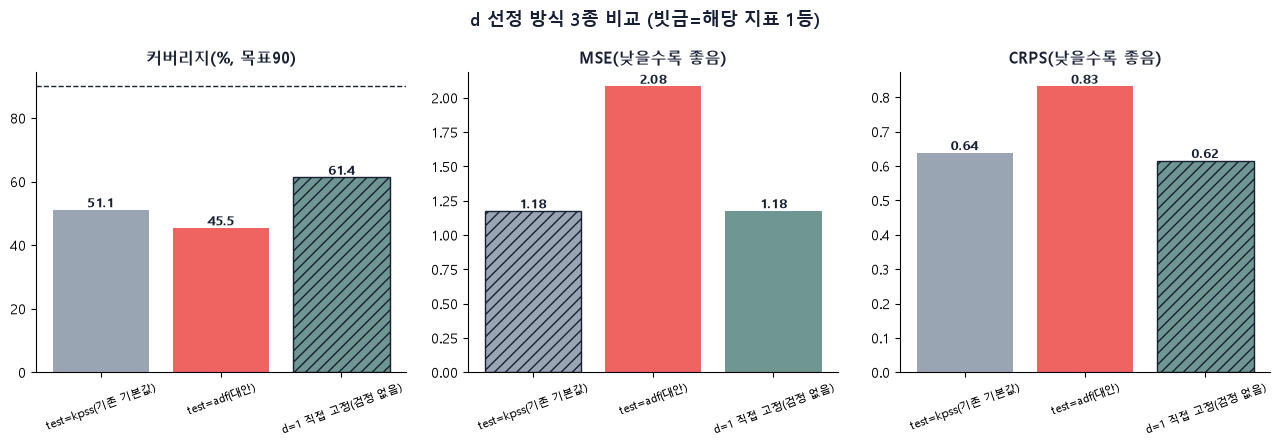

In [5]:
import matplotlib.pyplot as plt
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))
colors_d = {"test=kpss(기존 기본값)": "#9AA5B4", "test=adf(대안)": "#EF6461", "d=1 직접 고정(검정 없음)": "#6F9692"}
better_high_d = {"커버리지": True, "MSE": False, "CRPS": False}
for ax, metric, title in zip(axes, ["커버리지", "MSE", "CRPS"], ["커버리지(%, 목표90)", "MSE(낮을수록 좋음)", "CRPS(낮을수록 좋음)"]):
    bars = ax.bar(d_compare["방식"], d_compare[metric], color=[colors_d[m] for m in d_compare["방식"]])
    vals_m = d_compare[metric].values
    winner_idx = int(np.argmax(vals_m)) if better_high_d[metric] else int(np.argmin(vals_m))
    bars[winner_idx].set_hatch("///")
    bars[winner_idx].set_edgecolor("#172033")
    for bar, v in zip(bars, d_compare[metric]):
        ax.text(bar.get_x() + bar.get_width() / 2, v, f"{v:.2f}" if metric != "커버리지" else f"{v:.1f}",
                ha="center", va="bottom", fontsize=9, fontweight="bold", color="#172033")
    if metric == "커버리지":
        ax.axhline(90, color="#172033", linestyle="--", linewidth=1)
    ax.set_title(title, fontsize=11.5, fontweight="bold", color="#172033")
    ax.tick_params(axis="x", rotation=20, labelsize=8)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
fig.suptitle("d 선정 방식 3종 비교 (빗금=해당 지표 1등)", fontsize=13, fontweight="bold", color="#172033")
fig.tight_layout()
plt.show()


**결론(A)**: ADF는 더 나쁘다(과차분 남발) -- 이 표본크기에서 자동 단위근 검정 자체가 못 미덥다. 구조적 판단(랜덤워크)으로 **d=1 고정**이 커버리지·MSE·CRPS 세 지표 모두에서 가장 안정적이다.


## B. p 선택(AIC, GARCH동시/SV동시) 문제

GARCH동시/SV동시는 AR차수(p)를 AIC로 고르는데, 이게 믿을 만한지 확인한다.


In [6]:
def difference(values, d):
    x = np.asarray(values, dtype=float)
    hist = []
    for _ in range(d):
        hist.append(x.copy())
        x = np.diff(x)
    return x, hist


def is_ar_stable(ar_coefs):
    p = len(ar_coefs)
    if p == 0:
        return True
    companion = np.zeros((p, p))
    companion[0, :] = ar_coefs
    if p > 1:
        companion[1:, :-1] = np.eye(p - 1)
    return np.max(np.abs(np.linalg.eigvals(companion))) < 0.999


XI_MEAN, XI_VAR = -1.2704, np.pi ** 2 / 2
MAX_PHI = 0.97


def sv_qml_negloglik(z_centered, phi, sigma_eta2):
    P0 = sigma_eta2 / (1 - phi ** 2) if abs(phi) < 0.999 else sigma_eta2 * 100
    h_pred, P_pred, loglik = 0.0, P0, 0.0
    for z in z_centered:
        F = P_pred + XI_VAR
        v = z - h_pred
        loglik += -0.5 * (np.log(2 * np.pi * F) + v ** 2 / F)
        K = P_pred / F
        h_filt, P_filt = h_pred + K * v, P_pred * (1 - K)
        h_pred, P_pred = phi * h_filt, phi ** 2 * P_filt + sigma_eta2
    return -loglik


def joint_sv_negloglik(params, y_demeaned, p):
    ar_coefs = params[:p]
    phi = MAX_PHI * np.tanh(params[p])
    sigma_eta2 = np.exp(params[p + 1]) ** 2
    if not is_ar_stable(ar_coefs):
        return 1e10
    n = len(y_demeaned)
    resid = np.array([y_demeaned[t] - sum(ar_coefs[i] * y_demeaned[t - 1 - i] for i in range(p)) for t in range(p, n)])
    z = np.log(resid ** 2 + 1e-8)
    zc = z - z.mean()
    return sv_qml_negloglik(zc, phi, sigma_eta2)


def fit_garch_all_p(diff_train, max_p):
    aics = {}
    for p in range(1, max_p + 1):
        if len(diff_train) <= p + 3:
            continue
        am = arch_model(diff_train, mean="AR", lags=p, vol="GARCH", p=1, q=1, rescale=False)
        try:
            res = am.fit(disp="off")
        except Exception:
            continue
        aics[p] = res.aic
    return aics


def fit_sv_all_p(y, max_p):
    y_mean = y.mean()
    y_dm = y - y_mean
    aics = {}
    for p in range(1, max_p + 1):
        if len(y_dm) <= p + 3:
            continue
        x0 = [0.0] * p + [1.5, np.log(0.3)]
        res = minimize(joint_sv_negloglik, x0, args=(y_dm, p), method="Nelder-Mead", options={"maxiter": 3000})
        if not is_ar_stable(res.x[:p]) or res.fun >= 1e9:
            continue
        aics[p] = 2 * res.fun + 2 * len(x0)
    return aics


def best_p_within_cap(aics, cap):
    avail = {p: a for p, a in aics.items() if p <= cap}
    return min(avail, key=avail.get) if avail else None


P_DIAG_MAX = 6
CAP_CANDIDATES = [2, 3, 4, 5, 6]
CACHE_PDIAG = "../../cache/cache_83_p_selection_diag_df.pkl"

if os.path.exists(CACHE_PDIAG):
    pdiag_df = pd.read_pickle(CACHE_PDIAG)
    print(f"캐시에서 로드: {len(pdiag_df)}행")
else:
    rows_diag = []
    for origin in scored_origins:
        train = vals[:origin]
        diff_train, _ = difference(train, D_FIXED)
        garch_aics = fit_garch_all_p(diff_train, P_DIAG_MAX)
        sv_aics = fit_sv_all_p(diff_train, P_DIAG_MAX)
        row = {"origin": origin}
        for cap in CAP_CANDIDATES:
            # AR단독은 GARCH/SV처럼 "한 번에 다 구해놓고 사후에 상한만 낮춰서 재확인"이 안 된다
            # (auto_arima의 stepwise 탐색은 후보별 AIC 전체를 안 돌려준다) -- 그래서 상한마다 직접 재실행한다.
            m_ar_cap = pm.auto_arima(train, seasonal=False, suppress_warnings=True, error_action="ignore",
                                      d=D_FIXED, max_p=cap, start_q=0, max_q=0)
            row[f"AR_cap{cap}"] = m_ar_cap.order[0]
            row[f"GARCH_cap{cap}"] = best_p_within_cap(garch_aics, cap)
            row[f"SV_cap{cap}"] = best_p_within_cap(sv_aics, cap)
        rows_diag.append(row)
    pdiag_df = pd.DataFrame(rows_diag)
    os.makedirs(os.path.dirname(CACHE_PDIAG), exist_ok=True)
    pdiag_df.to_pickle(CACHE_PDIAG)
    print(f"새로 계산: {len(pdiag_df)}행")

print("AR단독(정확우도, q=0 강제, 상한=6일 때 선택분포):", pdiag_df["AR_cap6"].value_counts().to_dict())
print("\n상한(cap)별 각 모델이 '그 상한 자체'를 선택하는 비율(%):")
cap_rows = []
for cap in CAP_CANDIDATES:
    a_at_cap = 100 * (pdiag_df[f"AR_cap{cap}"] == cap).mean()
    g_at_cap = 100 * (pdiag_df[f"GARCH_cap{cap}"] == cap).mean()
    s_at_cap = 100 * (pdiag_df[f"SV_cap{cap}"] == cap).mean()
    cap_rows.append({"상한(cap)": cap, "AR단독이 상한 선택(%)": a_at_cap,
                      "GARCH가 상한 선택(%)": g_at_cap, "SV가 상한 선택(%)": s_at_cap})
cap_df = pd.DataFrame(cap_rows)
display(cap_df)


캐시에서 로드: 22행
AR단독(정확우도, q=0 강제, 상한=6일 때 선택분포): {1: 17, 2: 5}

상한(cap)별 각 모델이 '그 상한 자체'를 선택하는 비율(%):


,상한(cap),AR단독이 상한 선택(%),GARCH가 상한 선택(%),SV가 상한 선택(%)
0,2,22.727273,100.0,100.0
1,3,0.000000,100.0,100.0
2,4,0.000000,100.0,100.0
3,5,0.000000,100.0,100.0
4,6,0.000000,100.0,100.0


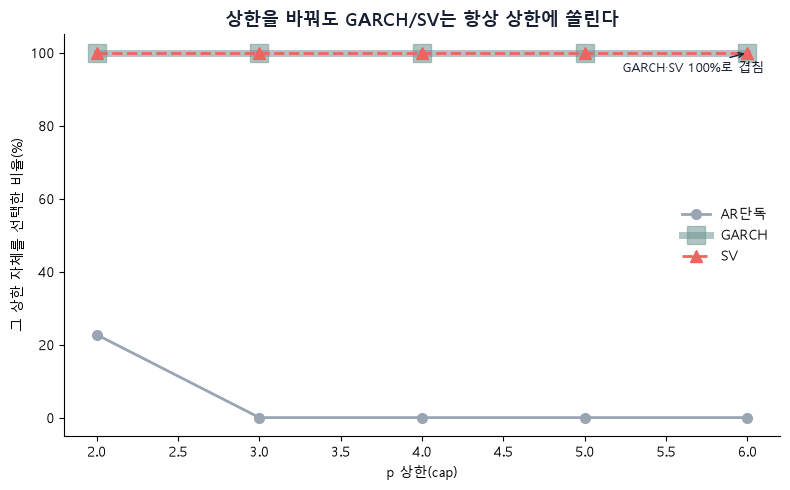

In [7]:
import matplotlib.pyplot as plt
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

fig, ax = plt.subplots(figsize=(8, 5))
styles = {
    "AR단독이 상한 선택(%)": dict(color="#9AA5B4", marker="o", linestyle="-", linewidth=2, markersize=7, zorder=3),
    "GARCH가 상한 선택(%)": dict(color="#6F9692", marker="s", linestyle="-", linewidth=5, markersize=13, alpha=0.55, zorder=1),
    "SV가 상한 선택(%)": dict(color="#EF6461", marker="^", linestyle="--", linewidth=2, markersize=8, zorder=2),
}
for col, style in styles.items():
    label = col.replace("이 상한 선택(%)", "").replace("가 상한 선택(%)", "")
    ax.plot(cap_df["상한(cap)"], cap_df[col], label=label, **style)
ax.annotate("GARCH·SV 100%로 겹침", xy=(cap_df["상한(cap)"].iloc[-1], 100), xytext=(-90, -14),
            textcoords="offset points", fontsize=9, color="#172033",
            arrowprops=dict(arrowstyle="->", color="#172033", lw=1))
ax.set_xlabel("p 상한(cap)")
ax.set_ylabel("그 상한 자체를 선택한 비율(%)")
ax.set_ylim(-5, 105)
ax.set_title("상한을 바꿔도 GARCH/SV는 항상 상한에 쏠린다", fontsize=13, fontweight="bold", color="#172033")
ax.legend(frameon=False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
plt.show()


**발견**: p상한을 2~6까지 뭘로 두든, GARCH동시·SV동시는 **그 상한 자체를 매번 100%(또는 거의 100%) 선택한다** -- 특정 p가 좋아서가 아니라 AIC가 p에 대해 단조증가로 개선되는 것처럼 보이는 계산상의 착시다. 반면 **AR단독(정확우도)은 상한을 낮춰도 선택분포가 항상 똑같다**(cap=2만 우연히 겹쳐 22.7%, cap=3 이상은 0%) -- 진짜로 p=1/2를 선호해서 멈추는 것이지 상한에 눌린 게 아니다.

**원인**: GARCH/SV는 조건부우도라 p가 커질수록 유효표본수(n-p)가 줄어 AIC 비교가 무효하다 -- d선택 때(A절)와 같은 함정이다.

## 결론

d(KPSS/ADF)와 p(GARCH/SV의 AIC) 둘 다, 이 표본크기(20~40개)·이 정도로 1에 가까운 자기상관(0.93)에서는 자동 선택 도구 자체를 못 믿는다는 게 커버리지·MSE·CRPS로 확인됐다.

**왜 d,p만 그리드서치가 필요한가**: GARCH/SV의 계수(ω,α,β / phi,sigma_eta)는 구조(GARCH(1,1), SV(1))가 고정된 채 연속값 하나를 찾는 문제라 MLE가 안정적으로 잘 찾는다 -- 이건 문제없다. 반면 d, p는 "구조 자체"를 고르는 이산선택 문제인데, 이걸 정하는 표준도구(KPSS/ADF/AIC)가 전부 이 데이터에서 못 미덥다는 게 위에서 증명됐다. 그래서 d, p **이 둘만** 후보를 몇 개로 좁혀(d,p 각각 0~2) out-of-sample 커버리지·MSE·CRPS로 직접 비교하는 그리드서치로 정하고, 나머지 파라미터는 평소대로 MLE에 맡긴다.

**다음 단계(분리)**: 이 d×p 그리드서치 계산은 `8-4`에서 이어간다(계산량이 커서 이번엔 여기까지).
